# Classical models: SVM and Random Forest

This notebook summarizes the classical pipeline's saved artifacts. It reads metrics, reports, confusion matrices, and feature importance from the five recorded runs; it does not retrain either model. Test evaluation is on the actor-independent split.

## Load project paths and libraries

Resolve the repository root so the notebook can be run with Jupyter from the project directory. Import the shared feature-family helper so family names match the training pipeline.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import ser_pipeline as sp

## Feature set and family counts

Count the numeric feature columns in the saved extended feature table and group them using the same family naming function as the classical pipeline. This makes the displayed counts traceable to the actual input file rather than a hand-entered summary.

In [2]:
features_path = ROOT / "outputs" / "features_v2.csv"
feature_columns = [c for c in pd.read_csv(features_path, nrows=0).columns if c not in sp.META_COLS]
grouped = {}
family_labels = {
    "mfcc": "MFCC + mean/std", "mfcc_delta": "Delta MFCC + mean/std",
    "mfcc_delta2": "Delta-delta MFCC + mean/std", "mel": "Log-Mel + mean/std",
    "chroma": "Chroma + mean/std", "contrast": "Spectral contrast + mean/std",
    "spectral_centroid": "Spectral centroid + mean/std",
    "spectral_bandwidth": "Spectral bandwidth + mean/std",
    "spectral_rolloff": "Spectral rolloff + mean/std", "zcr": "Zero-crossing rate + mean/std",
    "rms": "RMS energy + mean/std", "f0": "Pitch F0 mean/std",
    "f0_p10": "Pitch F0 percentile 10", "f0_p50": "Pitch F0 percentile 50",
    "f0_p90": "Pitch F0 percentile 90", "f0_absdiff": "Pitch F0 absolute change",
    "voiced_ratio": "Voiced-frame ratio", "duration": "Clip duration"
}
for name in feature_columns:
    base = sp.feature_family(name).rsplit(" ", 1)[0]
    label = family_labels.get(base, base)
    grouped[label] = grouped.get(label, 0) + 1
family_counts = pd.Series(grouped, name="Feature count").sort_values(ascending=False).to_frame()
display(family_counts)
print(f"Feature columns counted: {len(feature_columns)}")

,Feature count
MFCC + mean/std,80
Delta-delta MFCC + mean/std,80
Delta MFCC + mean/std,80
Log-Mel + mean/std,80
Chroma + mean/std,24
Spectral contrast + mean/std,14
Zero-crossing rate + mean/std,2
Spectral rolloff + mean/std,2
Spectral bandwidth + mean/std,2
Spectral centroid + mean/std,2


Feature columns counted: 376


## Five-run ablation: tuned SVM and Random Forest

Read the tuned-model rows from each saved run's `model_comparison.csv`. The folder names identify the no-augmentation and speaker-normalized variants. Speaker normalization can improve the aggregate test score, but it requires several clips from the same speaker and therefore cannot be used for a single uploaded clip.

In [3]:
run_folders = ["results", "results_v2_noaug", "results_v2", "results_v2_spknorm_noaug", "results_v2_spknorm"]
ablation_rows = []
for run in run_folders:
    comparison = pd.read_csv(ROOT / "outputs" / run / "model_comparison.csv")
    tuned = comparison[comparison["model"].isin(["SVM_tuned", "RF_tuned"])]
    for row in tuned.to_dict("records"):
        ablation_rows.append({
            "Run": run, "Model": row["model"], "Accuracy": row["accuracy"],
            "Precision (macro)": row["precision_macro"], "Recall (macro)": row["recall_macro"],
            "Macro-F1": row["f1_macro"]
        })
ablation = pd.DataFrame(ablation_rows)
display(ablation.style.format({c: "{:.3f}" for c in ["Accuracy", "Precision (macro)", "Recall (macro)", "Macro-F1"]}))

,Run,Model,Accuracy,Precision (macro),Recall (macro),Macro-F1
0,results,SVM_tuned,0.430,0.441,0.425,0.423
1,results,RF_tuned,0.437,0.443,0.425,0.419
2,results_v2_noaug,SVM_tuned,0.517,0.563,0.516,0.517
3,results_v2_noaug,RF_tuned,0.507,0.539,0.503,0.495
4,results_v2,SVM_tuned,0.553,0.594,0.556,0.554
5,results_v2,RF_tuned,0.477,0.498,0.491,0.473
6,results_v2_spknorm_noaug,SVM_tuned,0.590,0.598,0.603,0.587
7,results_v2_spknorm_noaug,RF_tuned,0.553,0.560,0.569,0.547
8,results_v2_spknorm,SVM_tuned,0.613,0.624,0.616,0.606
9,results_v2_spknorm,RF_tuned,0.567,0.601,0.588,0.561


## Tuned-model per-emotion reports

Display the SVM and Random Forest classification reports saved for the selected non-speaker-normalized `results_v2` run. The report includes per-class precision, recall, F1, and support.

In [4]:
for model_name in ("SVM_tuned", "RF_tuned"):
    report_path = ROOT / "outputs" / "results_v2" / f"classification_report_{model_name}.csv"
    print(model_name)
    report = pd.read_csv(report_path, index_col=0)
    display(report.round(3))

SVM_tuned


,precision,recall,f1-score,support
neutral,0.500,0.600,0.545,20.000
calm,0.651,0.700,0.675,40.000
happy,0.595,0.625,0.610,40.000
sad,0.270,0.500,0.351,40.000
angry,0.903,0.700,0.789,40.000
fearful,0.564,0.550,0.557,40.000
disgust,0.686,0.600,0.640,40.000
surprised,0.583,0.175,0.269,40.000
accuracy,0.553,0.553,0.553,0.553
macro avg,0.594,0.556,0.554,300.000


RF_tuned


,precision,recall,f1-score,support
neutral,0.341,0.700,0.459,20.000
calm,0.577,0.750,0.652,40.000
happy,0.514,0.450,0.480,40.000
sad,0.232,0.325,0.271,40.000
angry,0.727,0.600,0.658,40.000
fearful,0.474,0.225,0.305,40.000
disgust,0.524,0.550,0.537,40.000
surprised,0.591,0.325,0.419,40.000
accuracy,0.477,0.477,0.477,0.477
macro avg,0.498,0.491,0.473,300.000


## Confusion matrices

Show the saved tuned confusion-matrix figures. Rows are true classes and columns are predicted classes; each image also contains the row-normalized view created by the pipeline.

SVM_tuned


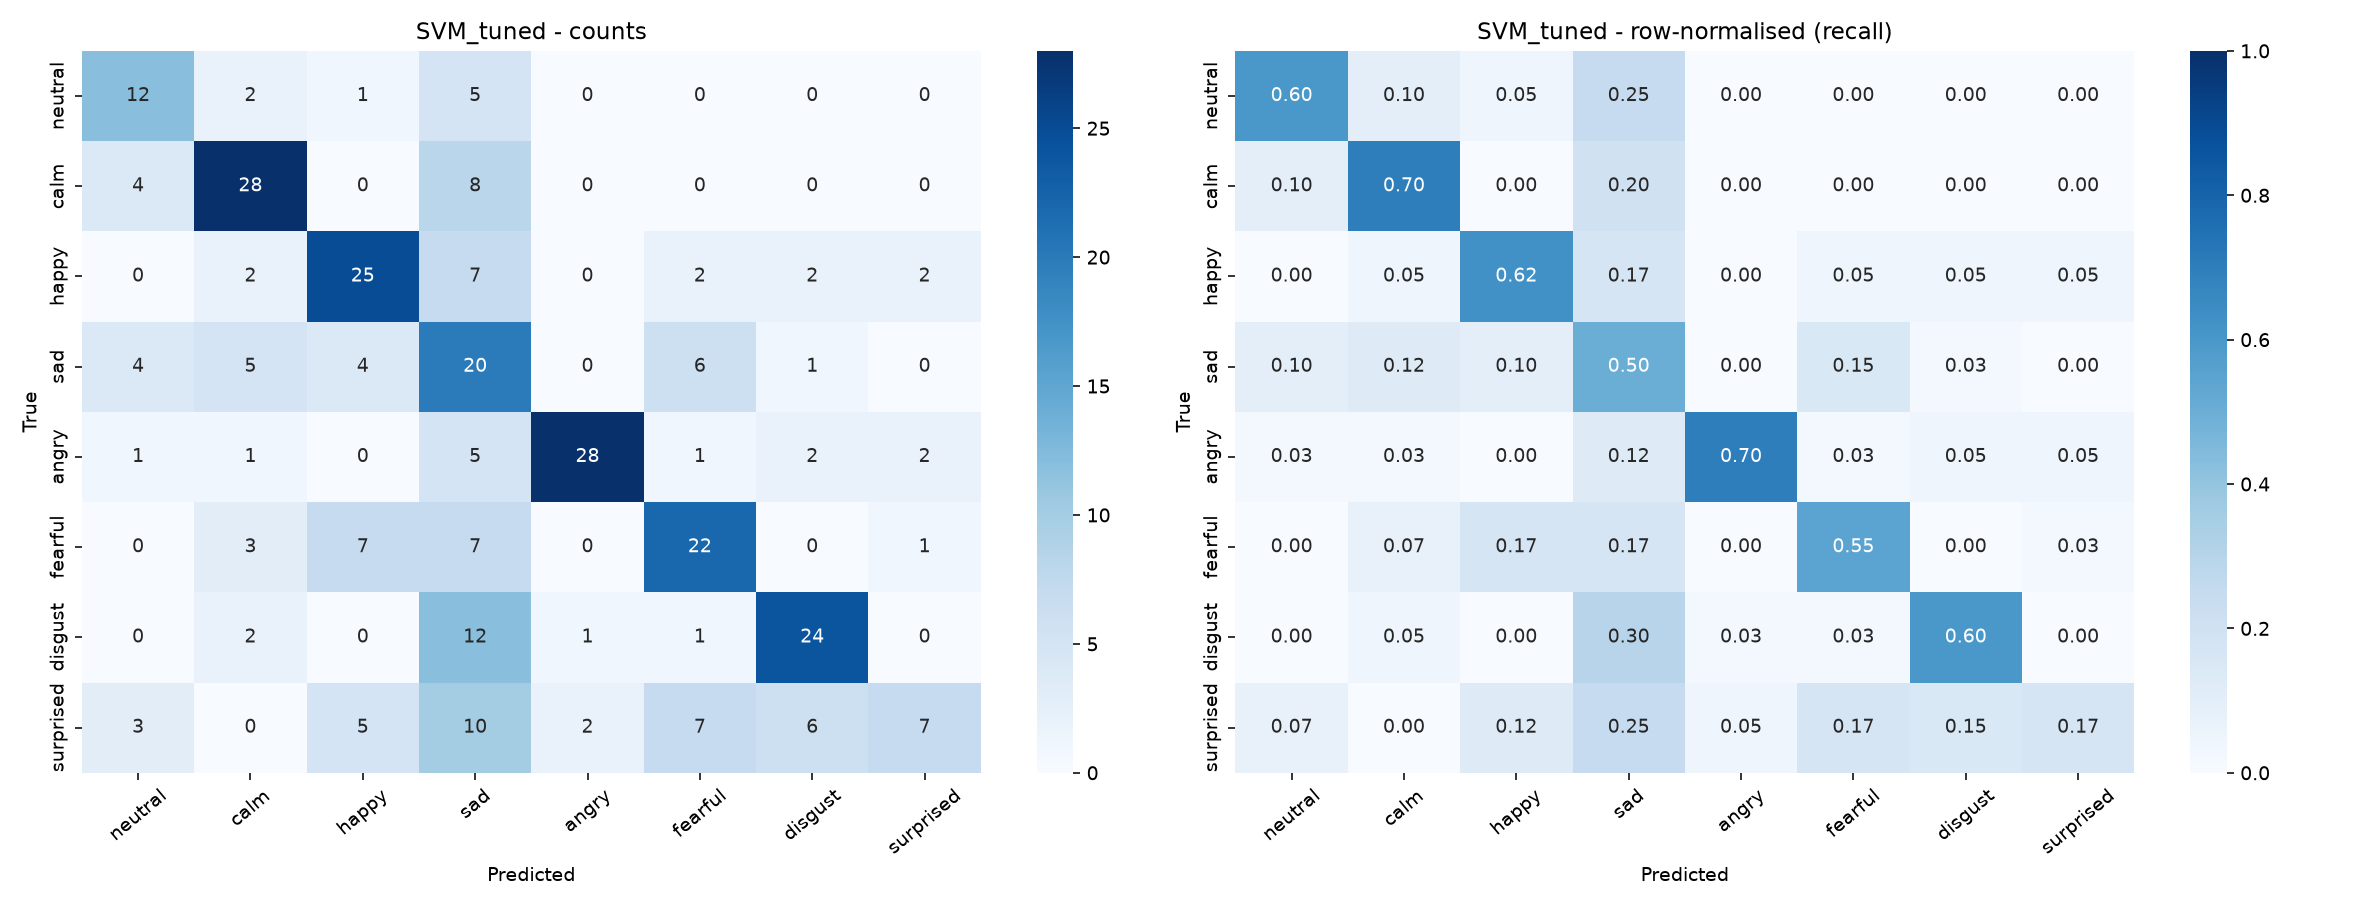

RF_tuned


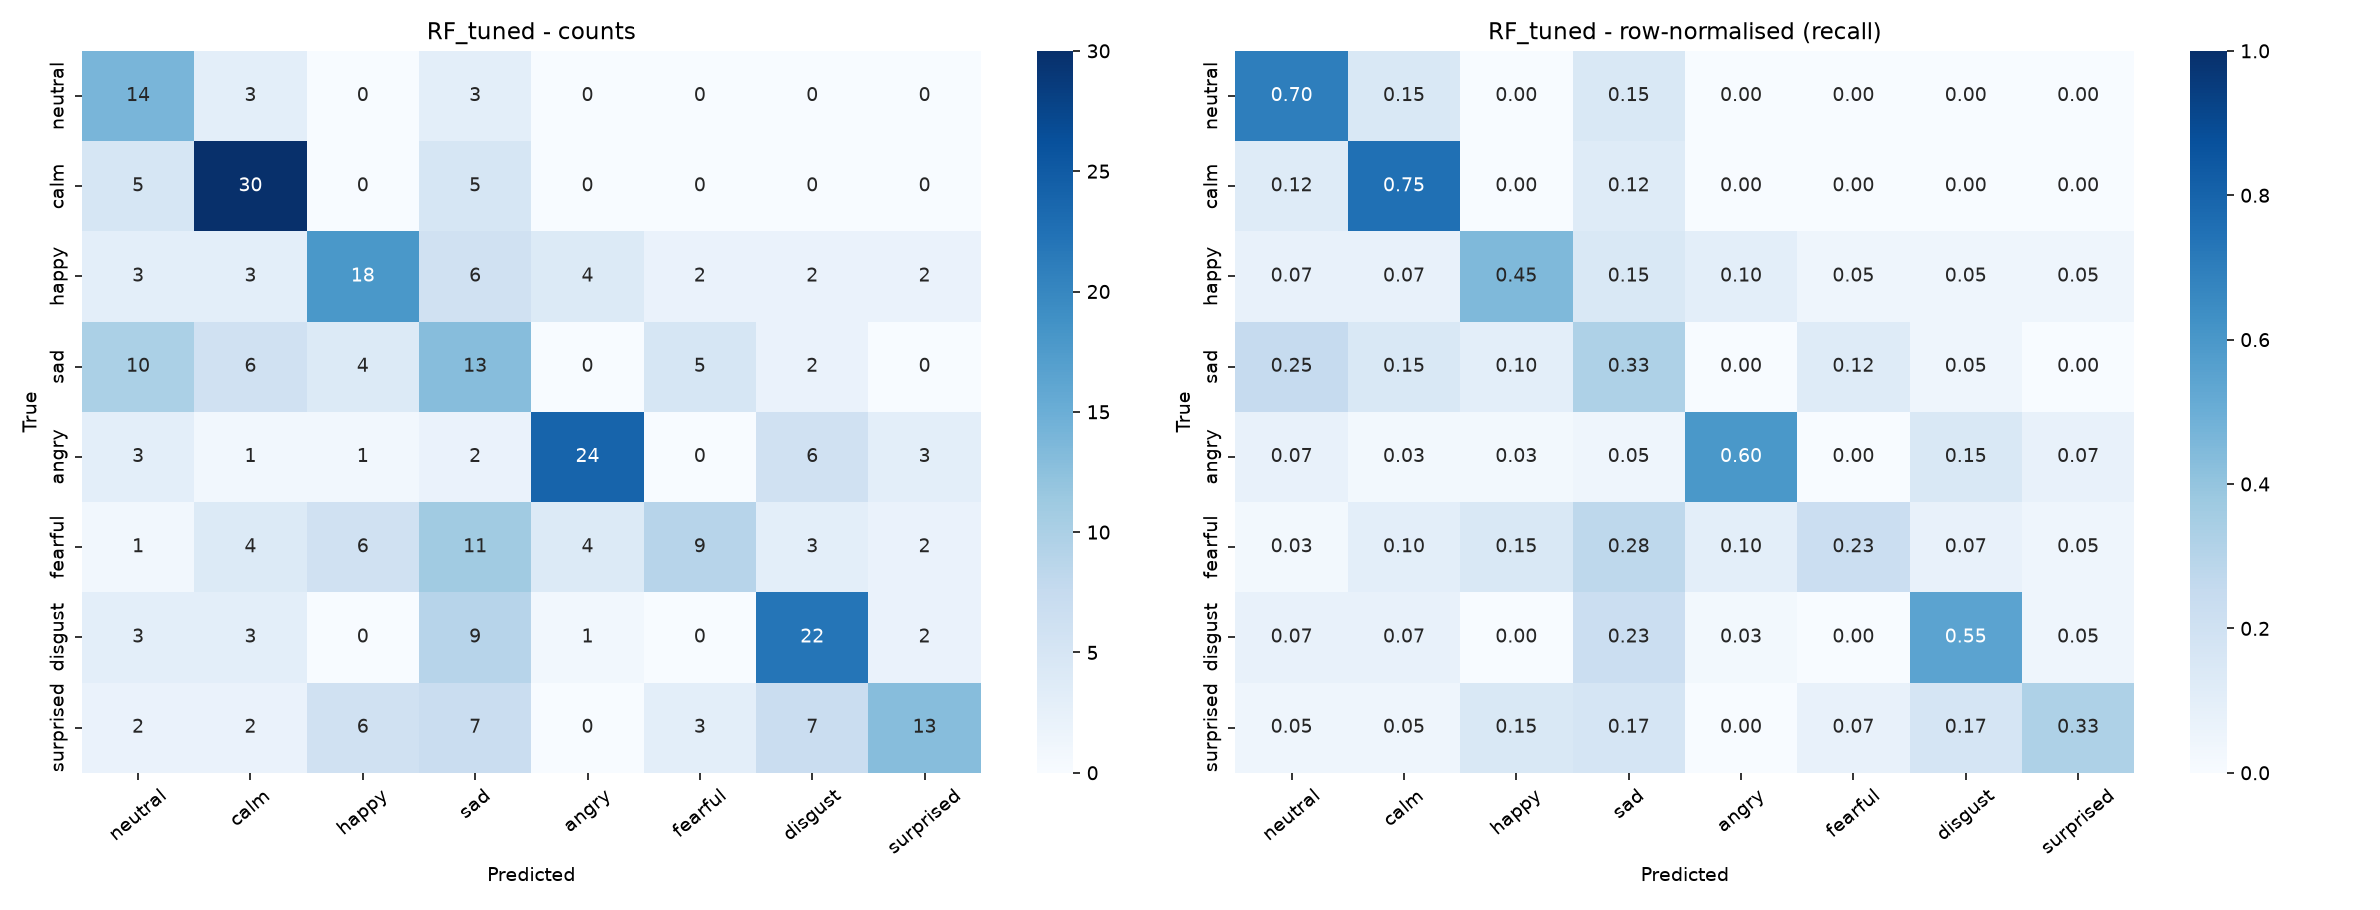

In [5]:
for model_name in ("SVM_tuned", "RF_tuned"):
    image_path = ROOT / "outputs" / "results_v2" / f"confusion_matrix_{model_name}.png"
    print(model_name)
    display(Image(filename=str(image_path)))

## Random Forest feature importance

Read the saved per-feature and aggregated-family importance tables and display the existing plot. Importance is descriptive of this fitted model, not a causal explanation.

,feature,importance,family
0,duration,0.02905,duration
1,f0_absdiff,0.02374,f0_absdiff
2,contrast_3_mean,0.01880,contrast mean
3,f0_mean,0.01587,f0 mean
4,mel_5_mean,0.01365,mel mean
5,f0_p50,0.01297,f0_p50
6,voiced_ratio,0.01237,voiced_ratio
7,mfcc_delta_4_mean,0.01155,mfcc_delta mean
8,mfcc_delta_6_std,0.01052,mfcc_delta std
9,f0_p90,0.00881,f0_p90


,family,importance
0,mel mean,0.12962
1,mfcc_delta mean,0.10343
2,mfcc mean,0.09550
3,mfcc_delta2 std,0.09110
4,mfcc_delta std,0.08845
5,mfcc std,0.08584
6,mel std,0.08184
7,mfcc_delta2 mean,0.07778
8,contrast mean,0.03737
9,chroma mean,0.02942


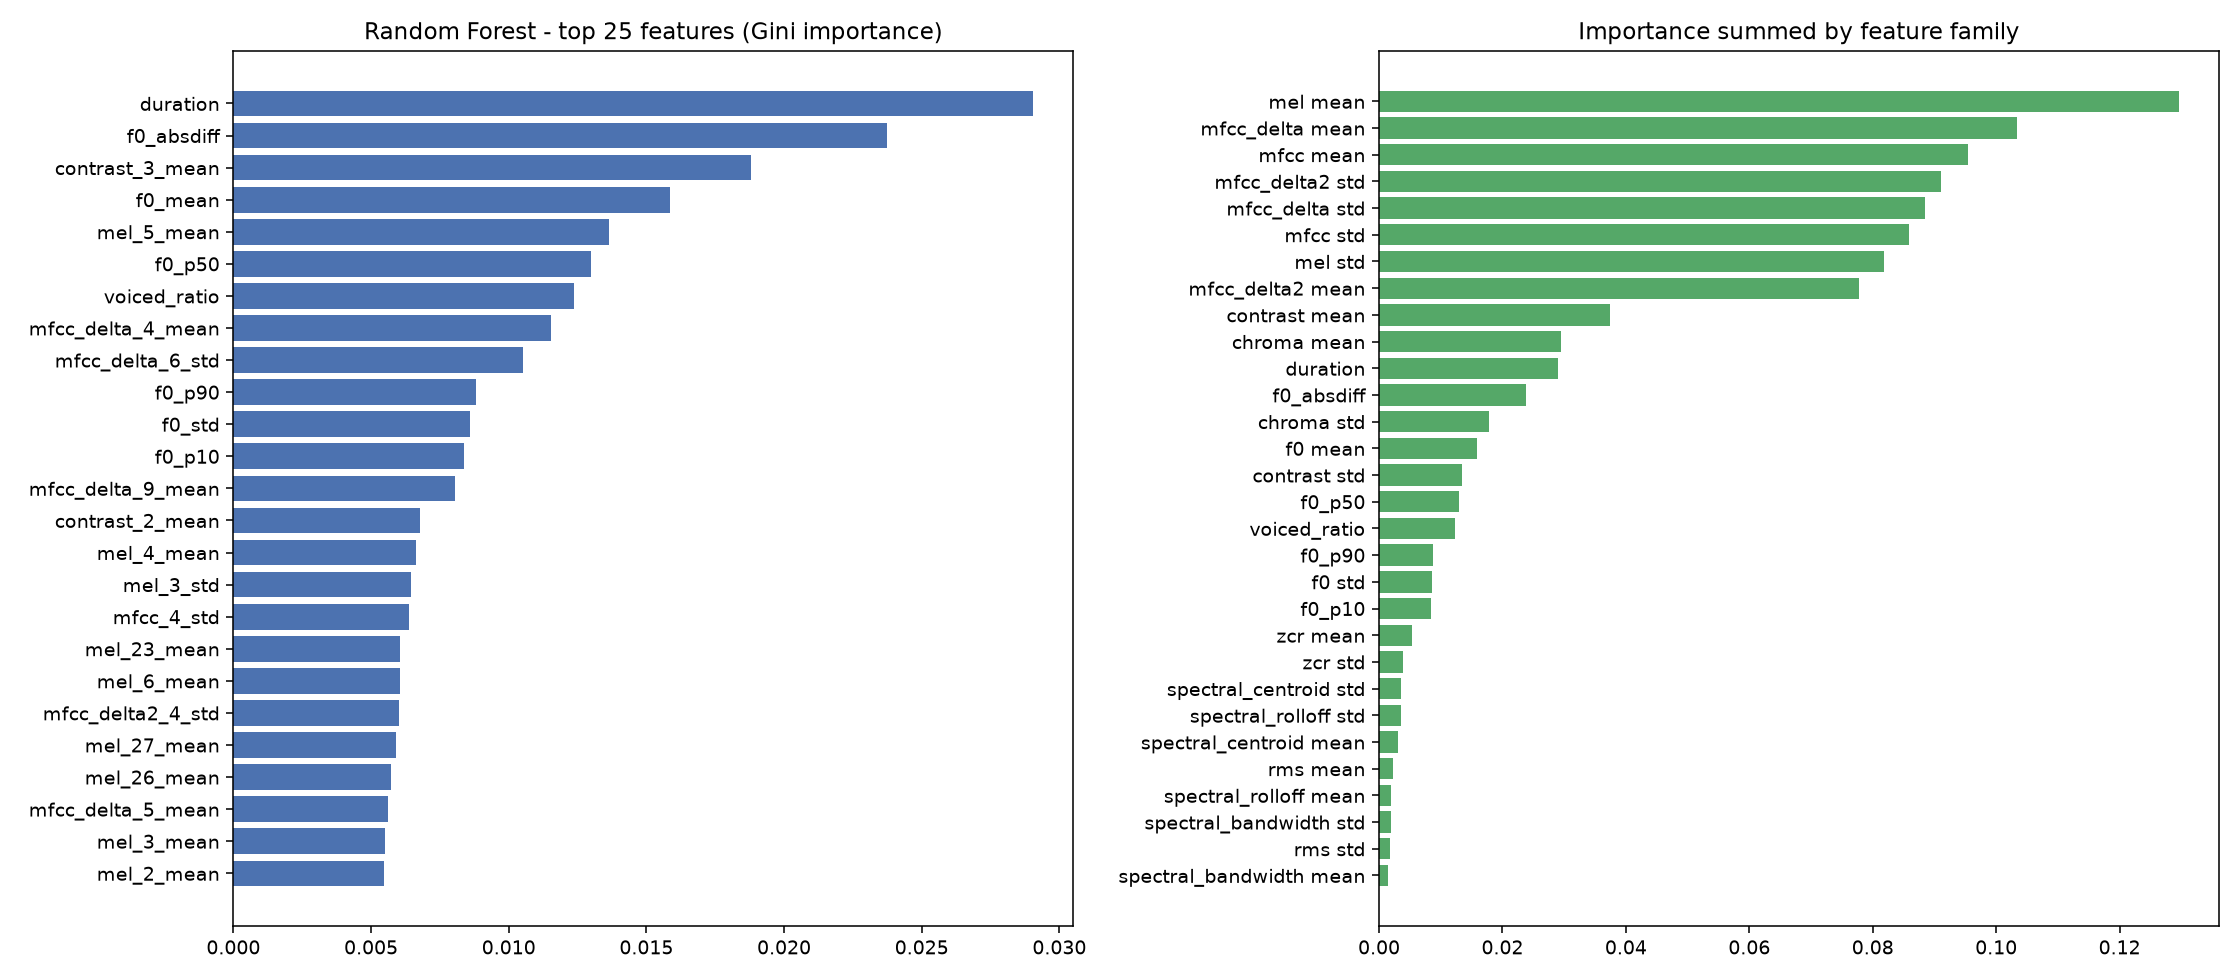

In [6]:
importance_path = ROOT / "outputs" / "results_v2" / "rf_feature_importance.csv"
importance = pd.read_csv(importance_path)
display(importance.head(20).round(5))
family_path = ROOT / "outputs" / "results_v2" / "rf_feature_importance_by_family.csv"
display(pd.read_csv(family_path).head(20).round(5))
display(Image(filename=str(ROOT / "outputs" / "results_v2" / "rf_feature_importance.png")))